# Analysis 4: Ghannoum et al. (2025)

### Topical Combination Therapy and Cutibacterium acnes Resistance

**Research Question**: How does long-term topical clindamycin/adapalene/benzoyl peroxide combination therapy relate to changes in C. acnes detection and clindamycin resistance?

**Source**: Ghannoum et al. (2025), Assessing Cutibacterium Acnes Susceptibility With Clindamycin Phosphate 1.2%/Adapalene 0.15%/Benzoyl Peroxide 3.1% Gel Use: Six-Month Analysis.

**Study Design**: Pooled analysis of two 24-week, open-label studies.

**Objective**: Use published aggregate data to describe changes in C. acnes detection and clindamycin susceptibility from baseline to Week 24.

**Important Limitation**: This is a descriptive secondary analysis. The original studies did not include a control group, so the findings cannot establish that the combination treatment prevented antibiotic resistance.

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Data extracted from Ghannoum et al. (2025), Figure 2, p. 1108
# Includes the 45 participants who completed the 24-week studies.

data = {
    "Category": [
        "No C. acnes detected",
        "Clindamycin-susceptible C. acnes",
        "Clindamycin-resistant C. acnes"
    ],
    "Baseline": [8, 32, 5],
    "Week 24": [25, 15, 5]
}

df = pd.DataFrame(data)

# Convert participant counts into percentages
df["Baseline (%)"] = df["Baseline"] / 45 * 100
df["Week 24 (%)"] = df["Week 24"] / 45 * 100

display(df)

# Verify that each time point includes 45 participants
assert df["Baseline"].sum() == 45
assert df["Week 24"].sum() == 45

print("Data validation passed!")


,Category,Baseline,Week 24,Baseline (%),Week 24 (%)
0,No C. acnes detected,8,25,17.777778,55.555556
1,Clindamycin-susceptible C. acnes,32,15,71.111111,33.333333
2,Clindamycin-resistant C. acnes,5,5,11.111111,11.111111


Data validation passed!


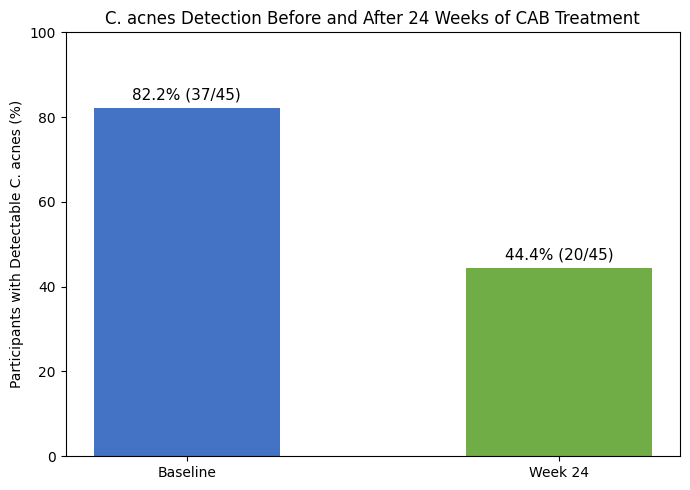

Change: -37.8 percentage points


In [ ]:

# Figure A: C. acnes detection rate at baseline and Week 24

timepoints = ["Baseline", "Week 24"]
detected = [37, 20]
total = 45

detection_rates = [n / total * 100 for n in detected]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    timepoints,
    detection_rates,
    color=["#4472C4", "#70AD47"],
    width=0.5
)

for bar, count, rate in zip(bars, detected, detection_rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{rate:.1f}% ({count}/45)",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "C. acnes Detection Before and After 24 Weeks of CAB Treatment"
)
ax.set_ylabel("Participants with Detectable C. acnes (%)")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig("analysis_4_figure_A_detection.png", dpi=300)
plt.show()

print(
    f"Change: {detection_rates[1] - detection_rates[0]:.1f} percentage points"
)


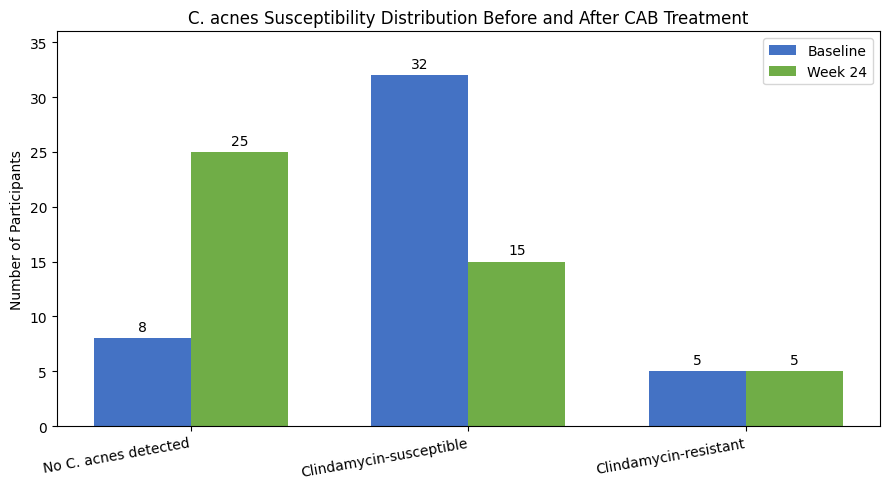

In [ ]:

# Figure B: C. acnes detection and clindamycin susceptibility

categories = [
    "No C. acnes detected",
    "Clindamycin-susceptible",
    "Clindamycin-resistant"
]

baseline = [8, 32, 5]
week24 = [25, 15, 5]

fig, ax = plt.subplots(figsize=(9, 5))

x = range(len(categories))
width = 0.35

bars1 = ax.bar(
    [i - width/2 for i in x],
    baseline,
    width,
    label="Baseline",
    color="#4472C4"
)

bars2 = ax.bar(
    [i + width/2 for i in x],
    week24,
    width,
    label="Week 24",
    color="#70AD47"
)

for bars in [bars1, bars2]:
    ax.bar_label(bars, padding=3)

ax.set_xticks(list(x))
ax.set_xticklabels(categories, rotation=10, ha="right")
ax.set_ylabel("Number of Participants")
ax.set_title(
    "C. acnes Susceptibility Distribution Before and After CAB Treatment"
)
ax.set_ylim(0, 36)
ax.legend()

plt.tight_layout()
plt.savefig("analysis_4_figure_B_susceptibility.png", dpi=300)
plt.show()


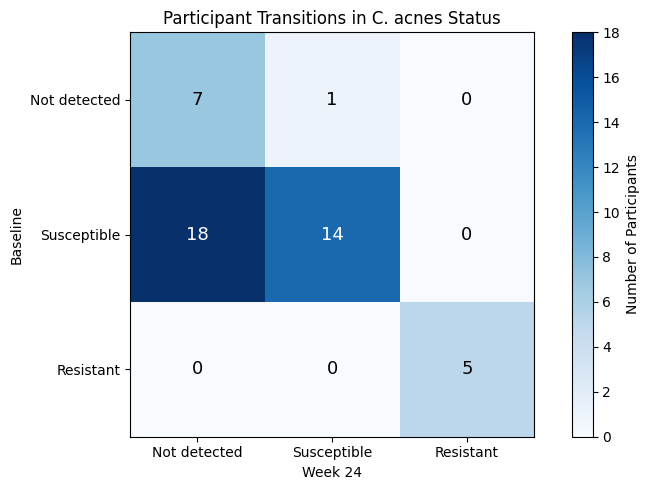

Week 24,Not detected,Susceptible,Resistant
Baseline,,,
Not detected,7,1,0
Susceptible,18,14,0
Resistant,0,0,5


In [4]:

# Figure C: Participant transitions from Baseline to Week 24
# Source: Ghannoum et al. (2025), Figure 2, p. 1108

import pandas as pd
import matplotlib.pyplot as plt

transitions = pd.DataFrame({
    "Baseline": [
        "Not detected",
        "Not detected",
        "Susceptible",
        "Susceptible",
        "Resistant"
    ],
    "Week 24": [
        "Not detected",
        "Susceptible",
        "Not detected",
        "Susceptible",
        "Resistant"
    ],
    "Participants": [7, 1, 18, 14, 5]
})

transition_matrix = transitions.pivot_table(
    index="Baseline",
    columns="Week 24",
    values="Participants",
    aggfunc="sum",
    fill_value=0
)

order = ["Not detected", "Susceptible", "Resistant"]
transition_matrix = transition_matrix.reindex(
    index=order,
    columns=order,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(transition_matrix.values, cmap="Blues")

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(order)
ax.set_yticklabels(order)

ax.set_xlabel("Week 24")
ax.set_ylabel("Baseline")
ax.set_title("Participant Transitions in C. acnes Status")

for i in range(3):
    for j in range(3):
        value = transition_matrix.iloc[i, j]
        ax.text(
            j, i, str(value),
            ha="center", va="center",
            color="white" if value > 10 else "black",
            fontsize=13
        )

plt.colorbar(im, ax=ax, label="Number of Participants")
plt.tight_layout()
plt.savefig("analysis_4_figure_C_transitions.png", dpi=300)
plt.show()

display(transition_matrix)


,Participant,Inflammatory Lesion Reduction (%),Noninflammatory Lesion Reduction (%)
0,P1,100,80
1,P2,82,53
2,P3,100,100
3,P4,100,57
4,P5,65,40


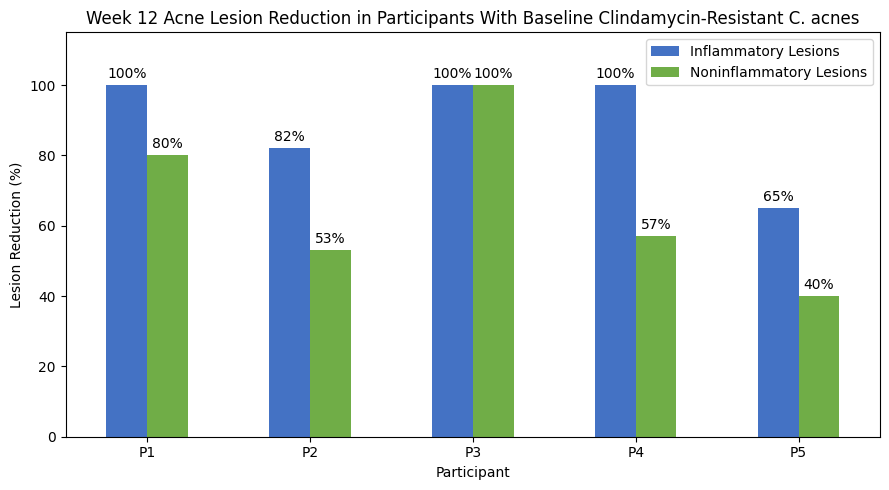

In [5]:

# Figure D: Clinical improvement in participants with resistant C. acnes
# Source: Ghannoum et al. (2025), Table 1, p. 1109
# Lesion reduction outcomes were measured at Week 12.

import pandas as pd
import matplotlib.pyplot as plt

resistant_patients = pd.DataFrame({
    "Participant": ["P1", "P2", "P3", "P4", "P5"],
    "Inflammatory Lesion Reduction (%)": [100, 82, 100, 100, 65],
    "Noninflammatory Lesion Reduction (%)": [80, 53, 100, 57, 40]
})

display(resistant_patients)

ax = resistant_patients.plot(
    x="Participant",
    y=[
        "Inflammatory Lesion Reduction (%)",
        "Noninflammatory Lesion Reduction (%)"
    ],
    kind="bar",
    figsize=(9, 5),
    color=["#4472C4", "#70AD47"],
    rot=0
)

ax.set_title(
    "Week 12 Acne Lesion Reduction in Participants "
    "With Baseline Clindamycin-Resistant C. acnes"
)
ax.set_ylabel("Lesion Reduction (%)")
ax.set_xlabel("Participant")
ax.set_ylim(0, 115)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=3)

plt.legend(
    ["Inflammatory Lesions", "Noninflammatory Lesions"]
)
plt.tight_layout()
plt.savefig("analysis_4_figure_D_lesion_reduction.png", dpi=300)
plt.show()


,Timepoint,C. acnes Positive,Clindamycin Resistant,Resistance (%)
0,Baseline,37,5,13.513514
1,Week 24,20,5,25.000000


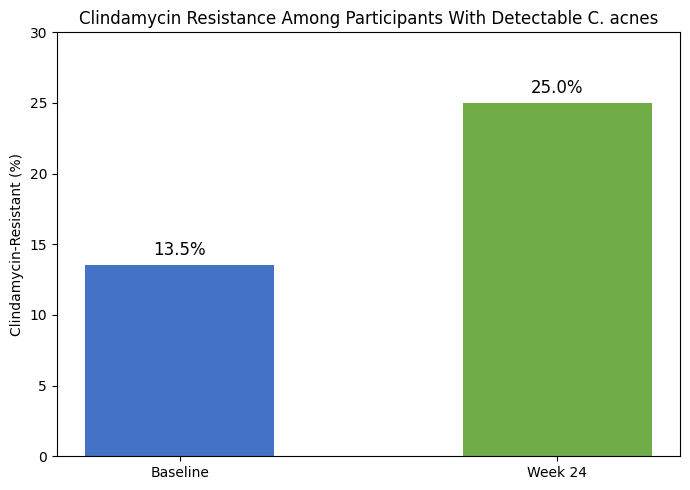

Baseline resistance: 13.5 %
Week 24 resistance: 25.0 %


In [6]:

# Figure E: Clindamycin resistance among C. acnes-positive participants
# Source: Ghannoum et al. (2025), Figure 2, p. 1108

import pandas as pd
import matplotlib.pyplot as plt

resistance_data = pd.DataFrame({
    "Timepoint": ["Baseline", "Week 24"],
    "C. acnes Positive": [37, 20],
    "Clindamycin Resistant": [5, 5]
})

resistance_data["Resistance (%)"] = (
    resistance_data["Clindamycin Resistant"]
    / resistance_data["C. acnes Positive"] * 100
)

display(resistance_data)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    resistance_data["Timepoint"],
    resistance_data["Resistance (%)"],
    color=["#4472C4", "#70AD47"],
    width=0.5
)

for bar, row in zip(bars, resistance_data.itertuples()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{row._4:.1f}%",
        ha="center",
        fontsize=12
    )

ax.set_title(
    "Clindamycin Resistance Among Participants "
    "With Detectable C. acnes"
)
ax.set_ylabel("Clindamycin-Resistant (%)")
ax.set_ylim(0, 30)

plt.tight_layout()
plt.savefig("analysis_4_figure_E_resistance_proportion.png", dpi=300)
plt.show()

print(
    "Baseline resistance:",
    round(resistance_data.loc[0, "Resistance (%)"], 1),
    "%"
)
print(
    "Week 24 resistance:",
    round(resistance_data.loc[1, "Resistance (%)"], 1),
    "%"
)


## Results

This analysis looked at changes in *Cutibacterium acnes* (*C. acnes*), a bacterium linked to acne, after 24 weeks of topical combination treatment with clindamycin, adapalene, and benzoyl peroxide.

**Figure A:** The number of participants with detectable *C. acnes* decreased from 37 out of 45 (82.2%) to 20 out of 45 (44.4%).

**Figure B:** The number of participants with clindamycin-susceptible bacteria decreased from 32 to 15. However, the number with clindamycin-resistant bacteria stayed at 5.

**Figure C:** All 5 participants who had resistant bacteria at the beginning still had resistant bacteria at Week 24. No new cases of detectable resistance were observed.

**Figure D:** All 5 participants with resistant bacteria at the beginning showed fewer acne lesions after 12 weeks of treatment.

**Figure E:** Among participants with detectable *C. acnes*, the percentage with resistant bacteria increased from 13.5% to 25.0%. This happened because fewer participants had detectable bacteria overall, not because new resistant cases appeared.

### Conclusion

Overall, fewer participants had detectable *C. acnes* after treatment, but the existing resistant bacteria were still detected. These results show that reducing bacteria does not always mean reducing antibiotic resistance.

Since this study used a combination of three treatments and had no control group, we cannot tell which ingredient caused the changes or whether the treatment prevented resistance.

In [7]:

# Save Analysis 4 data as CSV files

# Figure A & B: Detection and susceptibility data
df.to_csv("analysis_4_detection_susceptibility.csv", index=False)

# Figure C: Participant transitions
transition_matrix.to_csv("analysis_4_transitions.csv")

# Figure D: Clinical improvement in resistant participants
resistant_patients.to_csv(
    "analysis_4_resistant_patients.csv", index=False
)

# Figure E: Resistance proportions
resistance_data.to_csv(
    "analysis_4_resistance_proportions.csv", index=False
)

print("All 4 CSV files saved successfully!")


All 4 CSV files saved successfully!


In [8]:

import zipfile
from google.colab import files

zip_name = "Analysis_4_Ghannoum_2025.zip"

file_names = [
    "analysis_4_figure_A_detection.png",
    "analysis_4_figure_B_susceptibility.png",
    "analysis_4_figure_C_transitions.png",
    "analysis_4_figure_D_lesion_reduction.png",
    "analysis_4_figure_E_resistance_proportion.png",
    "analysis_4_detection_susceptibility.csv",
    "analysis_4_transitions.csv",
    "analysis_4_resistant_patients.csv",
    "analysis_4_resistance_proportions.csv"
]

with zipfile.ZipFile(zip_name, "w") as zipf:
    for filename in file_names:
        zipf.write(filename)

print("ZIP file created successfully!")
files.download(zip_name)


ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>